# TP 1 — Bases de PyTorch
**Chapitre 1 · Fondements de l'IA générative** — durée indicative : 1 h 30

Objectifs :
1. Manipuler les tenseurs : création, dimensions, opérations, broadcasting.
2. Comprendre `autograd` : graphe de calcul, `backward()`, gradients.
3. Écrire une descente de gradient à la main, puis avec `nn.Module` et un optimiseur.
4. Utiliser le CPU ou le GPU, sauvegarder et recharger un modèle.

> Installation : `pip install torch torchvision matplotlib`

In [1]:
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device :", device)

PyTorch 2.13.0+cpu | device : cpu


## 1. Tenseurs

In [2]:
a = torch.tensor([[1., 2., 3.], [4., 5., 6.]])
print(a.shape, a.dtype, a.ndim)

z = torch.zeros(2, 3); o = torch.ones(2, 3); r = torch.randn(2, 3)
print(torch.arange(0, 10, 2), torch.linspace(0, 1, 5))

print(a)
print(z)
print(o)
print(r)

print("----------------------")

# Opérations élément par élément vs produit matriciel
print(a * o)          # élément par élément
print(a @ a.T)        # (2,3) @ (3,2) -> (2,2)

# Changer la forme
print(a.view(3, 2).shape, a.reshape(-1).shape, a.unsqueeze(0).shape, a.T.shape)

torch.Size([2, 3]) torch.float32 2
tensor([0, 2, 4, 6, 8]) tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])
tensor([[1., 2., 3.],
        [4., 5., 6.]])
tensor([[0., 0., 0.],
        [0., 0., 0.]])
tensor([[1., 1., 1.],
        [1., 1., 1.]])
tensor([[ 0.3367,  0.1288,  0.2345],
        [ 0.2303, -1.1229, -0.1863]])
----------------------
tensor([[1., 2., 3.],
        [4., 5., 6.]])
tensor([[14., 32.],
        [32., 77.]])
torch.Size([3, 2]) torch.Size([6]) torch.Size([1, 2, 3]) torch.Size([3, 2])


### Broadcasting
Deux dimensions sont compatibles si elles sont égales ou si l'une vaut 1. Les dimensions sont comparées **de droite à gauche**.

In [3]:
x = torch.randn(4, 3)          # 4 échantillons, 3 variables
mu = x.mean(dim=0)              # (3,)
sigma = x.std(dim=0)            # (3,)
x_norm = (x - mu) / sigma       # (4,3) - (3,) -> (4,3)
print(x_norm.mean(0), x_norm.std(0))

col = torch.tensor([[1.], [2.]])   # (2,1)
row = torch.tensor([10., 20., 30.])  # (3,)
print(col + row)                   # (2,3)

tensor([-6.7055e-08, -2.9802e-08, -2.9802e-08]) tensor([1., 1., 1.])
tensor([[11., 21., 31.],
        [12., 22., 32.]])


**Exercice 1.** Sans boucle, calculez la matrice des distances euclidiennes entre les lignes de `P` (5×2) et celles de `Q` (3×2). Résultat attendu : forme (5,3). Vérifiez avec `torch.cdist`.

In [11]:
P, Q = torch.randn(5, 2), torch.randn(3, 2)
D = torch.cdist(P, Q)
print(torch.allclose(D, torch.cdist(P, Q), atol=1e-6))
print(P)
print(Q)
print(D)

True
tensor([[ 1.2818, -1.5952],
        [-1.0648,  0.1055],
        [ 1.9739,  1.0703],
        [-1.7379,  0.1841],
        [-0.1563, -0.6681]])
tensor([[ 1.2135,  0.7924],
        [-0.4401,  0.4996],
        [-0.7581,  0.9989]])
tensor([[2.3886, 2.7116, 3.3001],
        [2.3796, 0.7386, 0.9445],
        [0.8096, 2.4805, 2.7330],
        [3.0134, 1.3356, 1.2743],
        [2.0023, 1.2016, 1.7723]])


## 2. Autograd
Chaque opération sur un tenseur avec `requires_grad=True` est enregistrée dans un graphe. `backward()` applique la règle de dérivation en chaîne (rétropropagation).

In [12]:
x = torch.tensor(2.0, requires_grad=True)
y = x**3 + 2*x            # dy/dx = 3x² + 2 = 14
y.backward()
print(x.grad)

# Les gradients s'accumulent : il faut les remettre à zéro
y = x**3 + 2*x; y.backward(); print(x.grad)   # 28 !
x.grad.zero_()

# Désactiver le suivi (inférence, mise à jour des poids)
with torch.no_grad():
    print((x * 2).requires_grad)

tensor(14.)
tensor(28.)
False


**Exercice 2.** Pour $f(w, b) = (w\,x + b - y)^2$ avec $x=3$, $y=5$, $w=1$, $b=0$ : calculez à la main $\partial f/\partial w$ et $\partial f/\partial b$, puis vérifiez avec autograd.

In [17]:
# À compléter
x = torch.tensor(3.0)
y = torch.tensor(5.0)
w = torch.tensor(1.0, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)

f =  (w*x + b - y)**2
f.backward()

print(w.grad)
print(b.grad)

tensor(-12.)
tensor(-4.)


## 3. Régression linéaire : descente de gradient à la main

In [18]:
N = 100
X = torch.rand(N, 1) * 10
y = 2.5 * X + 1.0 + torch.randn(N, 1)       # vraie relation : w=2.5, b=1

w = torch.zeros(1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
lr = 0.01
for epoch in range(500):
    y_hat = X * w + b                 # forward
    loss = ((y_hat - y)**2).mean()    # MSE
    loss.backward()                   # gradients
    with torch.no_grad():             # mise à jour
        w -= lr * w.grad; b -= lr * b.grad
        w.grad.zero_(); b.grad.zero_()
    if epoch % 100 == 0: print(f"epoch {epoch:3d}  loss={loss.item():.3f}")
print("w =", w.item(), " b =", b.item())

epoch   0  loss=212.205
epoch 100  loss=1.083
epoch 200  loss=1.053
epoch 300  loss=1.044
epoch 400  loss=1.041
w = 2.5052926540374756  b = 1.0520758628845215


## 4. La même chose avec `nn.Module` et un optimiseur

In [19]:
class Lineaire(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(1, 1)
    def forward(self, x):
        return self.fc(x)

model = Lineaire().to(device)
opt = torch.optim.SGD(model.parameters(), lr=0.01)
loss_fn = nn.MSELoss()
Xd, yd = X.to(device), y.to(device)

for epoch in range(500):
    opt.zero_grad()
    loss = loss_fn(model(Xd), yd)
    loss.backward()
    opt.step()
print({k: v.flatten().tolist() for k, v in model.state_dict().items()})

{'fc.weight': [2.5065579414367676], 'fc.bias': [1.0439521074295044]}


**Exercice 3.** Remplacez `SGD` par `Adam` (lr=0.1) puis comparez les courbes de perte des deux optimiseurs sur un même graphique.

In [23]:
# À compléter
model2 = Lineaire().to(device)
opt2 = torch.optim.Adam(model.parameters(), lr =0.1)
loss_fn2 = nn.MSELoss()
Xd2, yd2 = X.to(device), y.to(device)

for epoch in range(500):
    opt2.zero_grad()
    loss = loss_fn2(model2(Xd2), yd2)
    loss.backward()
    opt2.step()
print({k: v.flatten().tolist() for k, v in model2.state_dict().items()})

{'fc.weight': [0.3112447261810303], 'fc.bias': [-0.7628720998764038]}


### comparison of SGD and Adam Optimisors

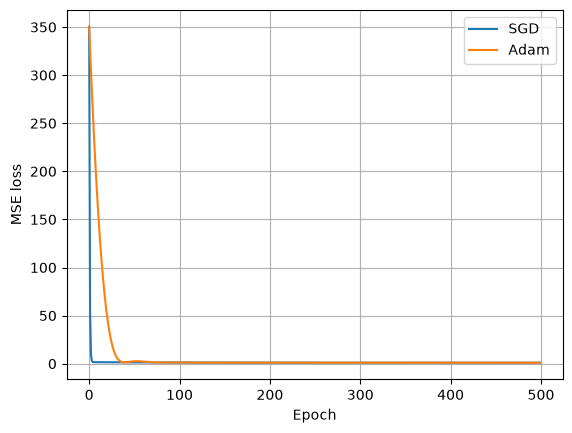

In [24]:
model_sgd = Lineaire().to(device)
model_adam = Lineaire().to(device)
model_adam.load_state_dict(model_sgd.state_dict())

opt_sgd = torch.optim.SGD(model_sgd.parameters(), lr=0.01)
opt_adam = torch.optim.Adam(model_adam.parameters(), lr=0.1)
losses_sgd, losses_adam = [], []

for _ in range(500):
    opt_sgd.zero_grad()
    loss_sgd = loss_fn(model_sgd(Xd), yd)
    loss_sgd.backward()
    opt_sgd.step()
    losses_sgd.append(loss_sgd.item())

    opt_adam.zero_grad()
    loss_adam = loss_fn(model_adam(Xd), yd)
    loss_adam.backward()
    opt_adam.step()
    losses_adam.append(loss_adam.item())

plt.plot(losses_sgd, label="SGD")
plt.plot(losses_adam, label="Adam")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.legend()
plt.grid(True)
plt.show()

## 5. Sauvegarde et chargement

In [25]:
torch.save(model.state_dict(), "lineaire.pt")       # on sauvegarde les poids, pas l'objet
m2 = Lineaire()
m2.load_state_dict(torch.load("lineaire.pt", map_location="cpu"))
m2.eval()
print(m2(torch.tensor([[4.0]])))

tensor([[11.0702]], grad_fn=<AddmmBackward0>)


## À retenir
- Boucle d'entraînement : `zero_grad` → forward → loss → `backward` → `step`.
- `torch.no_grad()` pour l'inférence ; `model.eval()` / `model.train()` changent le comportement de Dropout et BatchNorm.
- Modèle et données doivent être sur le même `device`.